# Victorian Electricity Demand: Weather Drivers

This notebook combines Victorian electricity demand with Melbourne weather data to investigate how temperature and other weather conditions relate to typical and extreme electricity demand.

## 1. Setup and Load Data

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

In [29]:
demand = pd.read_parquet(
    PROCESSED_DATA_DIR / "vic_demand_2025_30min.parquet"
)

weather = pd.read_parquet(
    PROCESSED_DATA_DIR / "melbourne_weather_2025_30min.parquet"
)

print("Demand shape:", demand.shape)
print("Weather shape:", weather.shape)

display(demand.head())
display(weather.head())

Demand shape: (17520, 2)
Weather shape: (17519, 6)


,datetime,demand_mw
0,2025-01-01 00:00:00,4281.094000
1,2025-01-01 00:30:00,4180.268333
2,2025-01-01 01:00:00,4093.626667
3,2025-01-01 01:30:00,3985.283333
4,2025-01-01 02:00:00,3876.845000


,datetime,temperature_c,relative_humidity,apparent_temperature_c,precipitation_mm,wind_speed_kmh
0,2025-01-01 00:00:00,16.650000,76.249390,16.708132,0.0,4.863332
1,2025-01-01 00:30:00,16.424999,78.267029,16.634514,0.0,4.224903
2,2025-01-01 01:00:00,16.200001,80.284676,16.560896,0.0,3.586474
3,2025-01-01 01:30:00,15.975000,81.862091,16.389101,0.0,3.395642
4,2025-01-01 02:00:00,15.750000,83.439499,16.217306,0.0,3.204809


## 2. Merge Demand and Weather

Join the 30-minute demand and weather datasets using their aligned timestamps.

In [30]:
combined = demand.merge(
    weather,
    on="datetime",
    how="left"
)

print("Combined shape:", combined.shape)

print("\nMissing values:")
print(combined.isna().sum())

display(combined.head())

Combined shape: (17520, 7)

Missing values:
datetime                  0
demand_mw                 0
temperature_c             1
relative_humidity         1
apparent_temperature_c    1
precipitation_mm          1
wind_speed_kmh            1
dtype: int64


,datetime,demand_mw,temperature_c,relative_humidity,apparent_temperature_c,precipitation_mm,wind_speed_kmh
0,2025-01-01 00:00:00,4281.094000,16.650000,76.249390,16.708132,0.0,4.863332
1,2025-01-01 00:30:00,4180.268333,16.424999,78.267029,16.634514,0.0,4.224903
2,2025-01-01 01:00:00,4093.626667,16.200001,80.284676,16.560896,0.0,3.586474
3,2025-01-01 01:30:00,3985.283333,15.975000,81.862091,16.389101,0.0,3.395642
4,2025-01-01 02:00:00,3876.845000,15.750000,83.439499,16.217306,0.0,3.204809


In [31]:
combined = combined.dropna(
    subset=[
        "temperature_c",
        "relative_humidity",
        "apparent_temperature_c",
        "precipitation_mm",
        "wind_speed_kmh"
    ]
).copy()

print("Final shape:", combined.shape)
print("Missing values:", combined.isna().sum().sum())

Final shape: (17519, 7)
Missing values: 0


## 3. Create Analysis Variables

In [32]:
combined["hour"] = (
    combined["datetime"].dt.hour
    + combined["datetime"].dt.minute / 60
)

combined["month"] = combined["datetime"].dt.month
combined["day_of_week"] = combined["datetime"].dt.day_name()
combined["is_weekend"] = combined["datetime"].dt.dayofweek >= 5

peak_threshold = combined["demand_mw"].quantile(0.99)
combined["is_peak"] = combined["demand_mw"] >= peak_threshold

print(f"Peak threshold: {peak_threshold:.1f} MW")
print(f"Peak observations: {combined['is_peak'].sum()}")

Peak threshold: 7825.5 MW
Peak observations: 176


## 4. Relationship Between Temperature and Demand

Investigate whether electricity demand changes systematically with temperature.

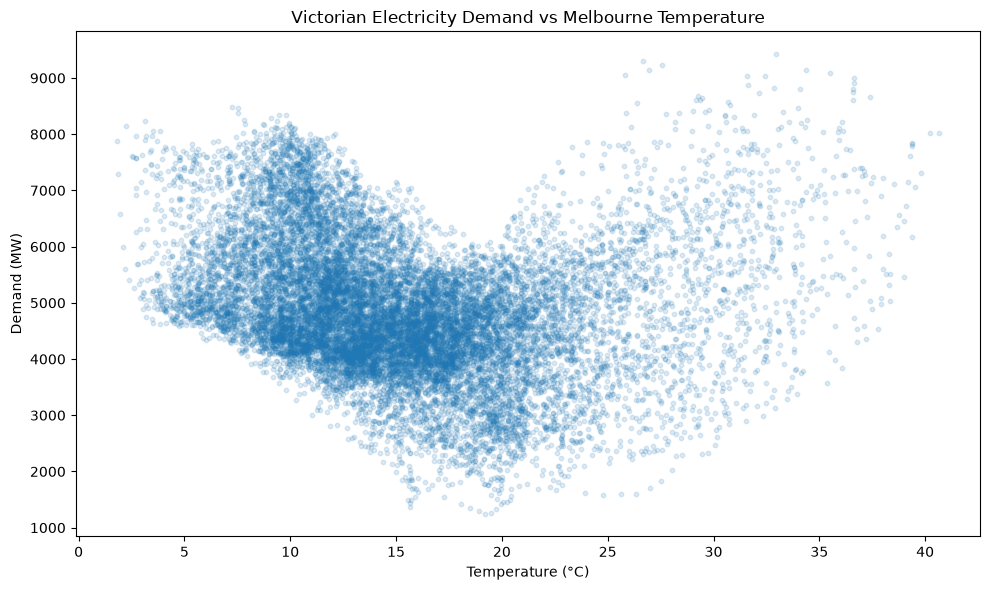

In [33]:
plt.figure(figsize=(10, 6))

plt.scatter(
    combined["temperature_c"],
    combined["demand_mw"],
    alpha=0.15,
    s=10
)

plt.title("Victorian Electricity Demand vs Melbourne Temperature")
plt.xlabel("Temperature (°C)")
plt.ylabel("Demand (MW)")
plt.tight_layout()

plt.show()

In [34]:
combined["temperature_bin"] = pd.cut(
    combined["temperature_c"],
    bins=np.arange(0, 43, 2),
    right=False
)

temperature_profile = (
    combined.groupby(
        "temperature_bin",
        observed=True
    )["demand_mw"]
    .agg(["mean", "median", "count"])
)

display(temperature_profile.round(1))

,mean,median,count
temperature_bin,,,
"[0, 2)",7250.8,7298.5,3
"[2, 4)",6090.0,5687.7,99
"[4, 6)",5630.6,5284.3,434
"[6, 8)",5607.0,5452.3,859
"[8, 10)",5600.5,5429.0,1719
"[10, 12)",5406.9,5207.0,2574
"[12, 14)",4869.9,4725.1,2616
"[14, 16)",4532.7,4486.4,2223
"[16, 18)",4318.5,4354.2,2123


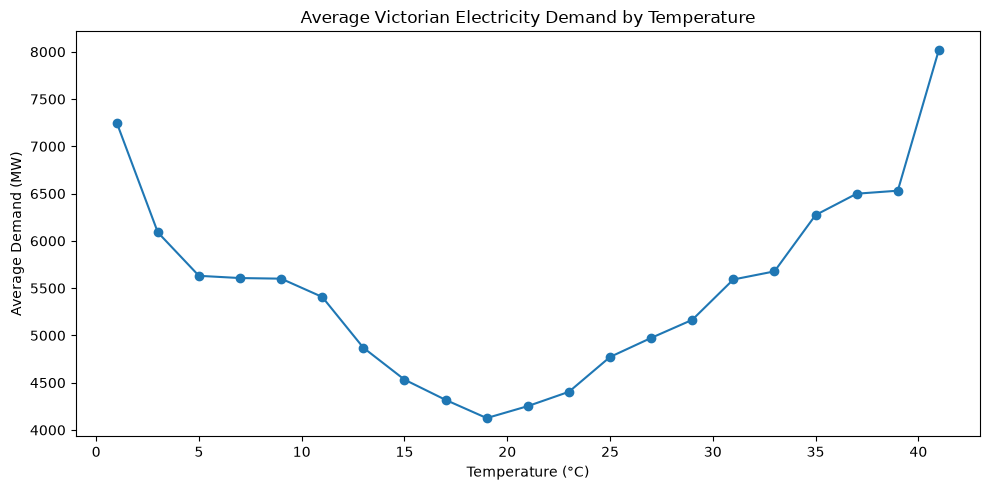

In [35]:
temperature_profile_plot = temperature_profile.reset_index()

temperature_profile_plot["temperature_midpoint"] = (
    temperature_profile_plot["temperature_bin"]
    .apply(lambda x: x.mid)
    .astype(float)
)

plt.figure(figsize=(10, 5))

plt.plot(
    temperature_profile_plot["temperature_midpoint"],
    temperature_profile_plot["mean"],
    marker="o"
)

plt.title("Average Victorian Electricity Demand by Temperature")
plt.xlabel("Temperature (°C)")
plt.ylabel("Average Demand (MW)")
plt.tight_layout()

plt.show()

In [36]:
def temperature_group(temp):
    if temp < 10:
        return "Cold (<10°C)"
    elif temp <= 25:
        return "Mild (10–25°C)"
    else:
        return "Hot (>25°C)"

combined["temperature_group"] = (
    combined["temperature_c"]
    .apply(temperature_group)
)

temperature_group_summary = (
    combined.groupby("temperature_group")["demand_mw"]
    .agg(["mean", "median", "max", "count"])
)

display(temperature_group_summary.round(1))

,mean,median,max,count
temperature_group,,,,
Cold (<10°C),5623.7,5420.1,8484.9,3114
Hot (>25°C),5345.5,5350.3,9421.4,1281
Mild (10–25°C),4659.7,4583.2,8135.1,13124


## 5. Temperature and Extreme Demand

Examine whether extreme electricity demand becomes more likely under unusually cold or hot conditions.

In [37]:
peak_by_temperature = (
    combined.groupby(
        "temperature_bin",
        observed=True
    )
    .agg(
        peak_rate=("is_peak", "mean"),
        observations=("is_peak", "size")
    )
    .reset_index()
)

peak_by_temperature["temperature_midpoint"] = (
    peak_by_temperature["temperature_bin"]
    .apply(lambda x: x.mid)
    .astype(float)
)

peak_by_temperature["peak_rate_pct"] = (
    peak_by_temperature["peak_rate"] * 100
)

display(
    peak_by_temperature[
        [
            "temperature_bin",
            "peak_rate_pct",
            "observations"
        ]
    ].round(2)
)

,temperature_bin,peak_rate_pct,observations
0,"[0, 2)",33.33,3
1,"[2, 4)",9.09,99
2,"[4, 6)",0.00,434
3,"[6, 8)",1.40,859
4,"[8, 10)",2.97,1719
5,"[10, 12)",1.09,2574
6,"[12, 14)",0.08,2616
7,"[14, 16)",0.00,2223
8,"[16, 18)",0.00,2123
9,"[18, 20)",0.00,1564


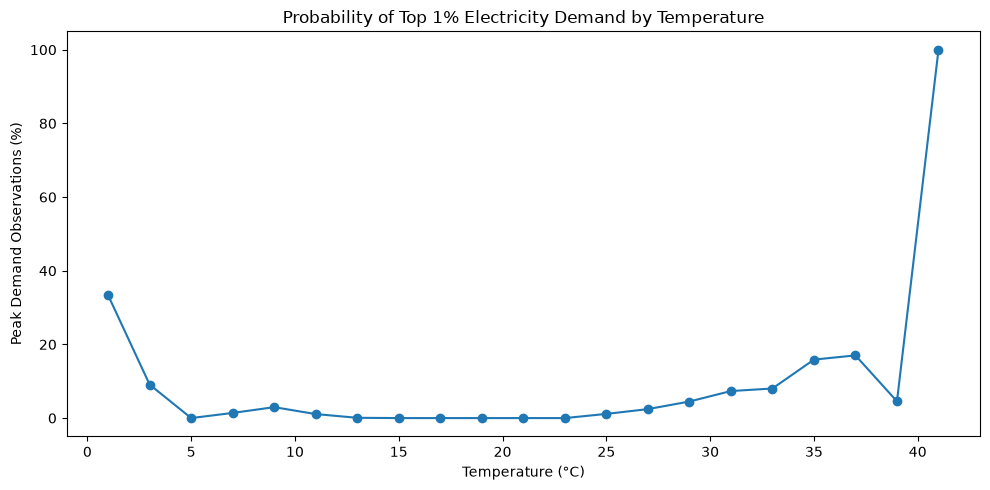

In [38]:
plt.figure(figsize=(10, 5))

plt.plot(
    peak_by_temperature["temperature_midpoint"],
    peak_by_temperature["peak_rate_pct"],
    marker="o"
)

plt.title("Probability of Top 1% Electricity Demand by Temperature")
plt.xlabel("Temperature (°C)")
plt.ylabel("Peak Demand Observations (%)")
plt.tight_layout()

plt.show()

## 6. Weather Conditions During Highest Demand Periods

In [39]:
top_demand_weather = (
    combined.nlargest(20, "demand_mw")
    [
        [
            "datetime",
            "demand_mw",
            "temperature_c",
            "apparent_temperature_c",
            "relative_humidity",
            "wind_speed_kmh"
        ]
    ]
)

display(top_demand_weather.round(1))

/var/folders/cq/ygq7nqrd04z8bh2mmmmknwx80000gn/T/ipykernel_27163/100693872.py:15: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(top_demand_weather.round(1))


,datetime,demand_mw,temperature_c,apparent_temperature_c,relative_humidity,wind_speed_kmh
1621,2025-02-03 18:30:00,9421.4,33.000000,33.799999,35.599998,7.000000
1571,2025-02-02 17:30:00,9307.0,26.700001,29.700001,74.500000,12.200000
1572,2025-02-02 18:00:00,9228.2,27.600000,30.400000,71.099998,13.500000
1620,2025-02-03 18:00:00,9148.4,34.400002,34.200001,27.000000,6.400000
1573,2025-02-02 18:30:00,9141.5,27.000000,29.500000,70.099998,12.900000
1619,2025-02-03 17:30:00,9095.2,35.500000,34.799999,23.299999,7.200000
1570,2025-02-02 17:00:00,9050.7,25.799999,28.900000,77.900002,11.000000
1622,2025-02-03 19:00:00,9043.1,31.600000,33.400002,44.200001,7.500000
2052,2025-02-12 18:00:00,9036.6,32.400002,32.400002,34.400002,10.900000
1618,2025-02-03 17:00:00,9005.8,36.599998,35.500000,19.700001,7.900000


## 7. Modelling Weather and Electricity Demand

The exploratory analysis suggests that electricity demand responds non-linearly to temperature, with higher demand under both cold and hot conditions. This section quantifies the relationship while accounting for recurring time-of-day and calendar patterns.

In [41]:
import statsmodels.formula.api as smf

model_data = combined.copy()

model_data["hour"] = model_data["datetime"].dt.hour
model_data["day_of_week"] = model_data["datetime"].dt.dayofweek
model_data["month"] = model_data["datetime"].dt.month

model_data["temp_squared"] = model_data["temperature_c"] ** 2

model_data[
    [
        "demand_mw",
        "temperature_c",
        "temp_squared",
        "relative_humidity",
        "wind_speed_kmh",
        "hour",
        "day_of_week",
        "month",
    ]
].head()

,demand_mw,temperature_c,temp_squared,relative_humidity,wind_speed_kmh,hour,day_of_week,month
0,4281.094000,16.650000,277.222473,76.249390,4.863332,0,2,1
1,4180.268333,16.424999,269.780609,78.267029,4.224903,0,2,1
2,4093.626667,16.200001,262.440033,80.284676,3.586474,1,2,1
3,3985.283333,15.975000,255.200638,81.862091,3.395642,1,2,1
4,3876.845000,15.750000,248.062500,83.439499,3.204809,2,2,1


In [42]:
weather_model = smf.ols(
    formula="""
        demand_mw ~ temperature_c
        + temp_squared
        + relative_humidity
        + wind_speed_kmh
        + C(hour)
        + C(day_of_week)
        + C(month)
    """,
    data=model_data
).fit()

print(weather_model.summary())

                            OLS Regression Results                            
Dep. Variable:              demand_mw   R-squared:                       0.749
Model:                            OLS   Adj. R-squared:                  0.749
Method:                 Least Squares   F-statistic:                     1188.
Date:                Sat, 22 Aug 2026   Prob (F-statistic):               0.00
Time:                        15:36:19   Log-Likelihood:            -1.3671e+05
No. Observations:               17519   AIC:                         2.735e+05
Df Residuals:                   17474   BIC:                         2.739e+05
Df Model:                          44                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept            4002.6350    

### 7.1 Model Performance and Temperature Effect

The model controls for recurring hourly, weekday and seasonal demand patterns while allowing electricity demand to respond non-linearly to temperature. Model performance and the estimated temperature-demand relationship are examined below.

In [43]:
print(f"Observations: {int(weather_model.nobs):,}")
print(f"R-squared: {weather_model.rsquared:.3f}")
print(f"Adjusted R-squared: {weather_model.rsquared_adj:.3f}")
print(f"RMSE: {(weather_model.mse_resid ** 0.5):,.1f} MW")

Observations: 17,519
R-squared: 0.749
Adjusted R-squared: 0.749
RMSE: 593.4 MW


In [44]:
import numpy as np
import pandas as pd

temperature_range = np.linspace(
    model_data["temperature_c"].quantile(0.01),
    model_data["temperature_c"].quantile(0.99),
    100
)

reference_data = pd.DataFrame({
    "temperature_c": temperature_range,
    "temp_squared": temperature_range ** 2,
    "relative_humidity": model_data["relative_humidity"].median(),
    "wind_speed_kmh": model_data["wind_speed_kmh"].median(),
    "hour": 18,
    "day_of_week": 2,
    "month": 2
})

reference_data["predicted_demand_mw"] = weather_model.predict(reference_data)

reference_data.head()

,temperature_c,temp_squared,relative_humidity,wind_speed_kmh,hour,day_of_week,month,predicted_demand_mw
0,4.550000,20.702502,70.533386,10.483554,18,2,2,6755.538614
1,4.839349,23.419295,70.533386,10.483554,18,2,2,6714.976990
2,5.128697,26.303534,70.533386,10.483554,18,2,2,6675.615373
3,5.418046,29.355218,70.533386,10.483554,18,2,2,6637.453763
4,5.707394,32.574346,70.533386,10.483554,18,2,2,6600.492160


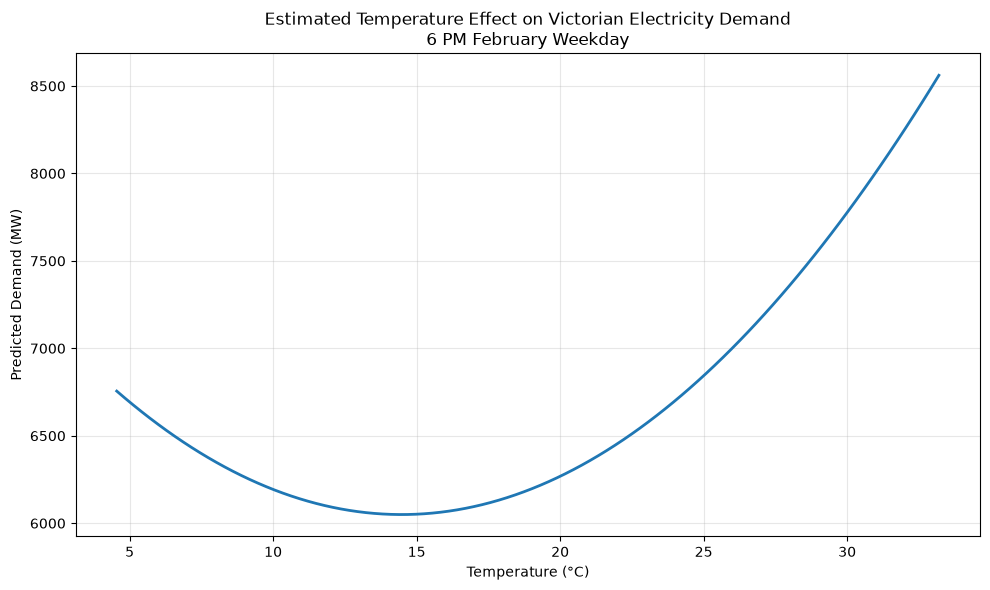

In [45]:
plt.figure(figsize=(10, 6))

plt.plot(
    reference_data["temperature_c"],
    reference_data["predicted_demand_mw"],
    linewidth=2
)

plt.xlabel("Temperature (°C)")
plt.ylabel("Predicted Demand (MW)")
plt.title(
    "Estimated Temperature Effect on Victorian Electricity Demand\n"
    "6 PM February Weekday"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Key Finding

After controlling for hour of day, day of week, month, humidity and wind speed, electricity demand shows a clear non-linear relationship with temperature. Predicted demand is lowest under mild conditions and increases at both colder and hotter temperatures, with the increase becoming particularly pronounced during hot conditions.

The model explains approximately 75% of observed variation in half-hourly demand in-sample. This result is descriptive rather than a measure of forecasting performance; out-of-sample forecasting is evaluated separately below.

## 8. Short-Term Electricity Demand Forecasting

This section evaluates whether recent demand patterns, calendar effects and weather conditions can be used to predict Victorian electricity demand.

Because electricity demand is time-dependent, observations are split chronologically rather than randomly. Models are trained using earlier observations and evaluated on unseen observations from the end of 2025.

In [46]:
forecast_data = combined.copy().sort_values("datetime").reset_index(drop=True)

# Calendar features
forecast_data["hour"] = forecast_data["datetime"].dt.hour
forecast_data["day_of_week"] = forecast_data["datetime"].dt.dayofweek
forecast_data["month"] = forecast_data["datetime"].dt.month
forecast_data["is_weekend"] = (
    forecast_data["day_of_week"] >= 5
).astype(int)

# Lagged demand features
# Data is at 30-minute intervals:
# 1 = 30 minutes ago
# 2 = 1 hour ago
# 48 = same time yesterday
# 336 = same time one week ago

forecast_data["lag_1"] = forecast_data["demand_mw"].shift(1)
forecast_data["lag_2"] = forecast_data["demand_mw"].shift(2)
forecast_data["lag_48"] = forecast_data["demand_mw"].shift(48)
forecast_data["lag_336"] = forecast_data["demand_mw"].shift(336)

# Recent demand trend
forecast_data["rolling_mean_6"] = (
    forecast_data["demand_mw"]
    .shift(1)
    .rolling(6)
    .mean()
)

forecast_data = forecast_data.dropna().reset_index(drop=True)

print("Forecasting observations:", len(forecast_data))
print("Start:", forecast_data["datetime"].min())
print("End:", forecast_data["datetime"].max())

forecast_data[
    [
        "datetime",
        "demand_mw",
        "temperature_c",
        "lag_1",
        "lag_2",
        "lag_48",
        "lag_336",
        "rolling_mean_6"
    ]
].head()

Forecasting observations: 17183
Start: 2025-01-08 00:00:00
End: 2025-12-31 23:00:00


,datetime,demand_mw,temperature_c,lag_1,lag_2,lag_48,lag_336,rolling_mean_6
0,2025-01-08 00:00:00,4135.958333,14.70,4262.855000,4255.015000,4010.278333,4281.094000,4301.822500
1,2025-01-08 00:30:00,4031.903333,14.50,4135.958333,4262.855000,3895.028333,4180.268333,4232.302778
2,2025-01-08 01:00:00,3985.985000,14.30,4031.903333,4135.958333,3782.748333,4093.626667,4172.885000
3,2025-01-08 01:30:00,3885.690000,14.05,3985.985000,4031.903333,3656.221667,3985.283333,4135.731667
4,2025-01-08 02:00:00,3858.500000,13.80,3885.690000,3985.985000,3557.686667,3876.845000,4092.901111


In [47]:
feature_columns = [
    "temperature_c",
    "relative_humidity",
    "apparent_temperature_c",
    "precipitation_mm",
    "wind_speed_kmh",
    "hour",
    "day_of_week",
    "month",
    "is_weekend",
    "lag_1",
    "lag_2",
    "lag_48",
    "lag_336",
    "rolling_mean_6"
]

print("Target:")
print("demand_mw")

print("\nPredictor variables:")
for feature in feature_columns:
    print("-", feature)

print("\nMissing values:")
print(forecast_data[feature_columns + ["demand_mw"]].isna().sum())

Target:
demand_mw

Predictor variables:
- temperature_c
- relative_humidity
- apparent_temperature_c
- precipitation_mm
- wind_speed_kmh
- hour
- day_of_week
- month
- is_weekend
- lag_1
- lag_2
- lag_48
- lag_336
- rolling_mean_6

Missing values:
temperature_c             0
relative_humidity         0
apparent_temperature_c    0
precipitation_mm          0
wind_speed_kmh            0
hour                      0
day_of_week               0
month                     0
is_weekend                0
lag_1                     0
lag_2                     0
lag_48                    0
lag_336                   0
rolling_mean_6            0
demand_mw                 0
dtype: int64


### 8.1 Chronological Train-Test Split

The final 30 days of observations are reserved as an unseen test period. All model training uses only observations occurring before the test period, preserving the temporal ordering of the data and preventing future observations from leaking into model training.

In [48]:
test_start = forecast_data["datetime"].max() - pd.Timedelta(days=30)

train = forecast_data[
    forecast_data["datetime"] < test_start
].copy()

test = forecast_data[
    forecast_data["datetime"] >= test_start
].copy()

print("Training period:")
print(train["datetime"].min(), "to", train["datetime"].max())
print("Observations:", len(train))

print("\nTest period:")
print(test["datetime"].min(), "to", test["datetime"].max())
print("Observations:", len(test))

Training period:
2025-01-08 00:00:00 to 2025-12-01 22:30:00
Observations: 15742

Test period:
2025-12-01 23:00:00 to 2025-12-31 23:00:00
Observations: 1441


### 8.2 Baseline Forecasts

Two simple forecasting rules are used as benchmarks:

1. **Persistence:** assume demand in the next period will equal demand 30 minutes earlier.
2. **Weekly seasonal baseline:** assume demand will equal demand at the same time one week earlier.

A more complex forecasting model should outperform these simple benchmarks to demonstrate practical value.

In [49]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

test["persistence_forecast"] = test["lag_1"]
test["weekly_forecast"] = test["lag_336"]

def evaluate_forecast(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = np.mean(
        np.abs((actual - predicted) / actual)
    ) * 100

    return mae, rmse, mape

persistence_metrics = evaluate_forecast(
    test["demand_mw"],
    test["persistence_forecast"]
)

weekly_metrics = evaluate_forecast(
    test["demand_mw"],
    test["weekly_forecast"]
)

baseline_results = pd.DataFrame(
    {
        "Model": [
            "30-minute persistence",
            "Same time previous week"
        ],
        "MAE (MW)": [
            persistence_metrics[0],
            weekly_metrics[0]
        ],
        "RMSE (MW)": [
            persistence_metrics[1],
            weekly_metrics[1]
        ],
        "MAPE (%)": [
            persistence_metrics[2],
            weekly_metrics[2]
        ]
    }
)

baseline_results.round(2)

,Model,MAE (MW),RMSE (MW),MAPE (%)
0,30-minute persistence,144.98,184.25,3.69
1,Same time previous week,743.51,1156.11,22.19


### 8.3 Random Forest Forecasting Model

A Random Forest regression model is trained using weather conditions, calendar effects, recent electricity demand, weekly demand patterns, and rolling demand information.

The model is evaluated only on the held-out final 30 days of 2025 and compared against the baseline forecasts.

In [50]:
from sklearn.ensemble import RandomForestRegressor

feature_cols = [
    "temperature_c",
    "relative_humidity",
    "apparent_temperature_c",
    "precipitation_mm",
    "wind_speed_kmh",
    "hour",
    "day_of_week",
    "month",
    "is_weekend",
    "lag_1",
    "lag_2",
    "lag_48",
    "lag_336",
    "rolling_mean_6"
]

X_train = train[feature_cols]
y_train = train["demand_mw"]

X_test = test[feature_cols]
y_test = test["demand_mw"]

rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=18,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest training complete.")

Random Forest training complete.


### 8.4 Out-of-Sample Forecast Performance

In [51]:
rf_metrics = evaluate_forecast(
    y_test,
    rf_predictions
)

model_results = pd.DataFrame({
    "Model": [
        "30-minute persistence",
        "Same time previous week",
        "Random Forest"
    ],
    "MAE (MW)": [
        persistence_metrics[0],
        weekly_metrics[0],
        rf_metrics[0]
    ],
    "RMSE (MW)": [
        persistence_metrics[1],
        weekly_metrics[1],
        rf_metrics[1]
    ],
    "MAPE (%)": [
        persistence_metrics[2],
        weekly_metrics[2],
        rf_metrics[2]
    ]
})

model_results.round(2)

,Model,MAE (MW),RMSE (MW),MAPE (%)
0,30-minute persistence,144.98,184.25,3.69
1,Same time previous week,743.51,1156.11,22.19
2,Random Forest,87.08,122.33,2.47


### 8.5 Feature Importance

Feature importance is examined to identify which weather, temporal, and historical demand variables contribute most strongly to the Random Forest forecasts.

In [52]:
feature_importance = pd.DataFrame({
    "feature": feature_cols,
    "importance": rf_model.feature_importances_
}).sort_values("importance", ascending=False)

feature_importance

,feature,importance
9,lag_1,0.968022
10,lag_2,0.013417
13,rolling_mean_6,0.008996
5,hour,0.004249
11,lag_48,0.000839
12,lag_336,0.000818
4,wind_speed_kmh,0.000724
0,temperature_c,0.000705
2,apparent_temperature_c,0.000668
1,relative_humidity,0.000616


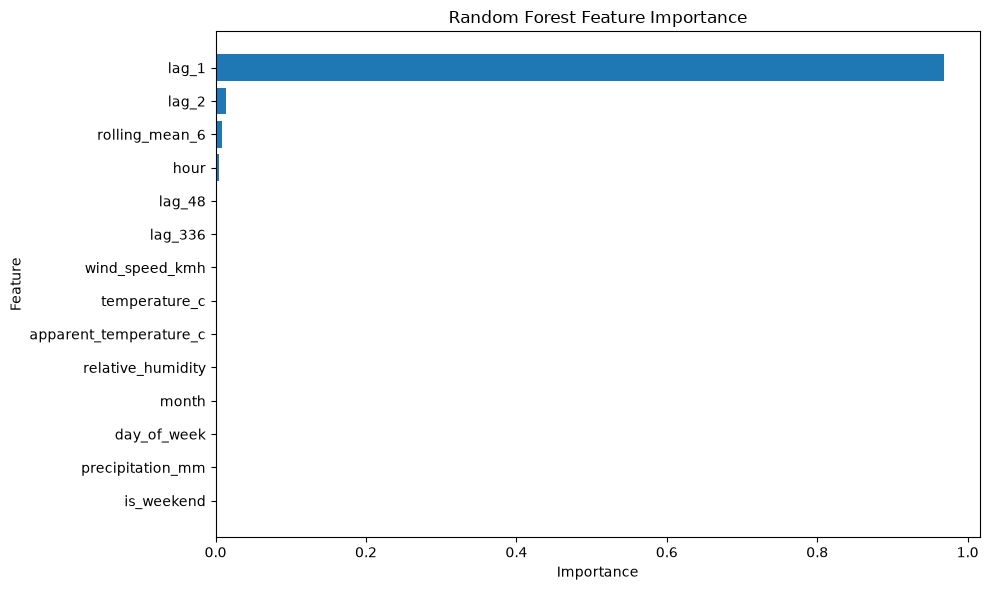

In [53]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["feature"],
    feature_importance["importance"]
)

plt.gca().invert_yaxis()

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

### 8.6 Performance During Peak Demand

Overall forecast accuracy can hide poor performance during periods of unusually high electricity demand. Because peak-demand periods are particularly important for electricity-system planning, model performance is evaluated separately for the highest-demand observations in the test period.

In [56]:
test_results = test[["datetime", "demand_mw"]].copy()

# 30-minute persistence forecast = previous demand observation
test_results["persistence_prediction"] = test["lag_1"].values

# Random Forest forecast
test_results["rf_prediction"] = rf_predictions

# Define peak demand as top 5% of actual demand in test period
peak_threshold = test_results["demand_mw"].quantile(0.95)

peak_test = test_results[
    test_results["demand_mw"] >= peak_threshold
].copy()

# Evaluate forecasts during peak-demand periods
persistence_peak_metrics = evaluate_forecast(
    peak_test["demand_mw"],
    peak_test["persistence_prediction"]
)

rf_peak_metrics = evaluate_forecast(
    peak_test["demand_mw"],
    peak_test["rf_prediction"]
)

peak_results = pd.DataFrame({
    "Model": [
        "30-minute persistence",
        "Random Forest"
    ],
    "MAE (MW)": [
        persistence_peak_metrics[0],
        rf_peak_metrics[0]
    ],
    "RMSE (MW)": [
        persistence_peak_metrics[1],
        rf_peak_metrics[1]
    ],
    "MAPE (%)": [
        persistence_peak_metrics[2],
        rf_peak_metrics[2]
    ]
})

print(f"Peak-demand threshold: {peak_threshold:.1f} MW")
print(f"Peak observations: {len(peak_test)}")

peak_results.round(2)

Peak-demand threshold: 5945.2 MW
Peak observations: 73


,Model,MAE (MW),RMSE (MW),MAPE (%)
0,30-minute persistence,208.97,253.29,3.19
1,Random Forest,120.49,158.90,1.84


### 8.7 Actual vs Forecast Electricity Demand

The Random Forest forecast is compared with observed electricity demand over the held-out test period. This provides a visual assessment of how closely the model tracks short-term demand movements.

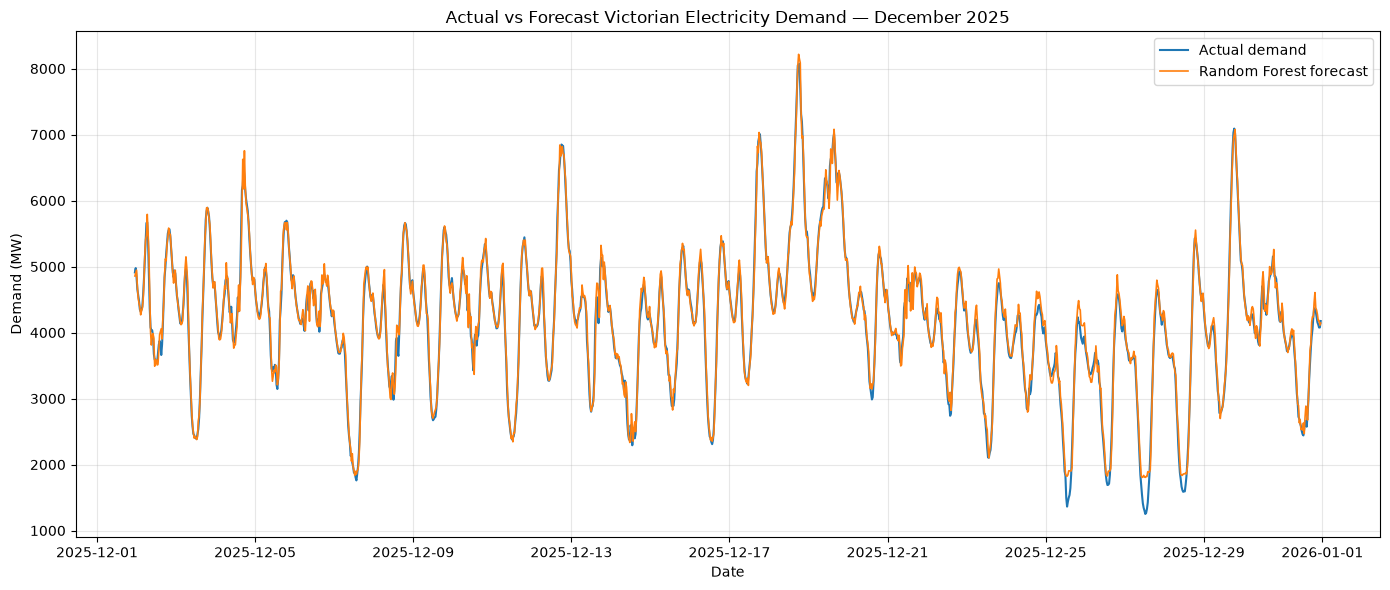

In [57]:
plot_results = test_results.copy()

plt.figure(figsize=(14, 6))

plt.plot(
    plot_results["datetime"],
    plot_results["demand_mw"],
    label="Actual demand",
    linewidth=1.5
)

plt.plot(
    plot_results["datetime"],
    plot_results["rf_prediction"],
    label="Random Forest forecast",
    linewidth=1.2
)

plt.title("Actual vs Forecast Victorian Electricity Demand — December 2025")
plt.xlabel("Date")
plt.ylabel("Demand (MW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

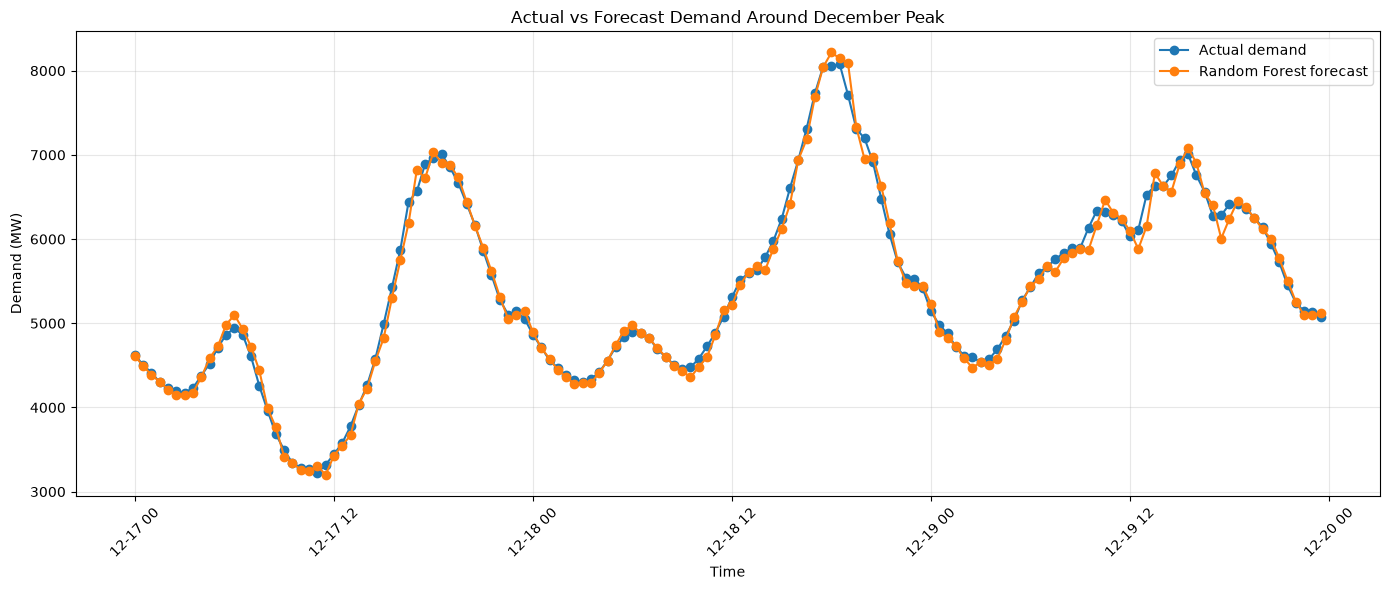

Peak demand date: 2025-12-18


In [58]:
peak_day = test_results.loc[
    test_results["demand_mw"].idxmax(),
    "datetime"
].date()

peak_window = test_results[
    (test_results["datetime"].dt.date >= peak_day - pd.Timedelta(days=1)) &
    (test_results["datetime"].dt.date <= peak_day + pd.Timedelta(days=1))
].copy()

plt.figure(figsize=(14, 6))

plt.plot(
    peak_window["datetime"],
    peak_window["demand_mw"],
    marker="o",
    label="Actual demand"
)

plt.plot(
    peak_window["datetime"],
    peak_window["rf_prediction"],
    marker="o",
    label="Random Forest forecast"
)

plt.title("Actual vs Forecast Demand Around December Peak")
plt.xlabel("Time")
plt.ylabel("Demand (MW)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Peak demand date:", peak_day)

### 8.8 Forecast Error Analysis

Forecast errors are analysed across the held-out test period to identify when the model performs poorly and whether errors vary systematically by time of day.

Understanding these failure cases is important because average performance metrics alone can conceal periods in which forecasts are less reliable.

In [59]:
error_analysis = test_results.copy()

error_analysis["error"] = (
    error_analysis["rf_prediction"] -
    error_analysis["demand_mw"]
)

error_analysis["absolute_error"] = error_analysis["error"].abs()

error_analysis["hour"] = error_analysis["datetime"].dt.hour

print("Mean forecast error:", round(error_analysis["error"].mean(), 2), "MW")
print("Median absolute error:", round(error_analysis["absolute_error"].median(), 2), "MW")

largest_errors = (
    error_analysis
    .nlargest(10, "absolute_error")
    [["datetime", "demand_mw", "rf_prediction", "error", "absolute_error"]]
)

largest_errors.round(2)

Mean forecast error: 29.06 MW
Median absolute error: 60.39 MW


/var/folders/cq/ygq7nqrd04z8bh2mmmmknwx80000gn/T/ipykernel_27163/550815662.py:21: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  largest_errors.round(2)


,datetime,demand_mw,rf_prediction,error,absolute_error
16969,2025-12-27 12:30:00,1251.61,1806.63,555.02,555.02
16970,2025-12-27 13:00:00,1266.42,1818.84,552.42,552.42
16968,2025-12-27 12:00:00,1301.39,1810.53,509.14,509.14
16967,2025-12-27 11:30:00,1344.29,1835.83,491.54,491.54
16971,2025-12-27 13:30:00,1328.76,1817.88,489.11,489.11
16305,2025-12-13 16:30:00,4142.77,4619.85,477.08,477.08
16972,2025-12-27 14:00:00,1428.20,1892.59,464.39,464.39
16874,2025-12-25 13:00:00,1363.20,1823.65,460.45,460.45
16154,2025-12-10 13:00:00,3824.40,3366.95,-457.44,457.44
16301,2025-12-13 14:30:00,4132.21,3687.42,-444.79,444.79


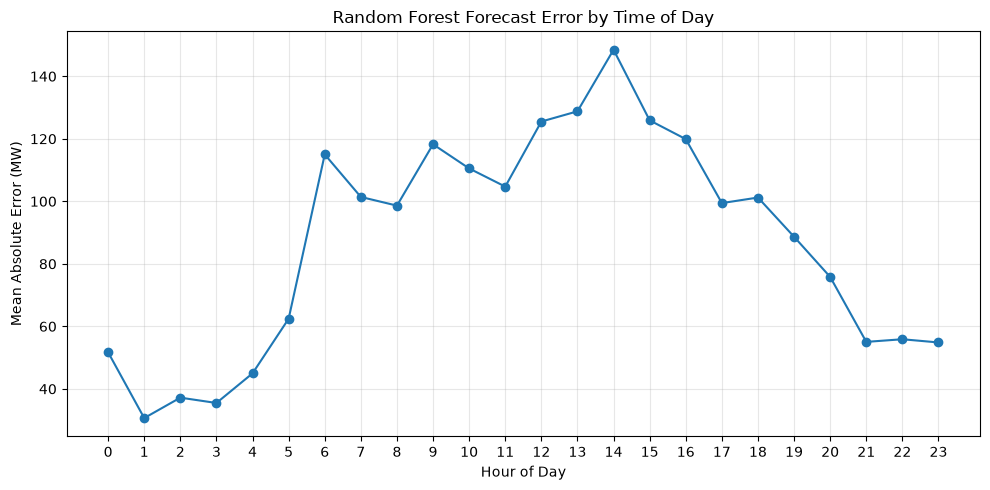

In [60]:
hourly_error = (
    error_analysis
    .groupby("hour")["absolute_error"]
    .mean()
)

plt.figure(figsize=(10, 5))

plt.plot(
    hourly_error.index,
    hourly_error.values,
    marker="o"
)

plt.title("Random Forest Forecast Error by Time of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Mean Absolute Error (MW)")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [61]:
import holidays

# Victorian public holidays
vic_holidays = holidays.Australia(
    years=[2025],
    subdiv="VIC"
)

forecast_data["is_public_holiday"] = (
    forecast_data["datetime"]
    .dt.date
    .isin(vic_holidays)
    .astype(int)
)

# Check the holidays appearing in our dataset
forecast_data.loc[
    forecast_data["is_public_holiday"] == 1,
    ["datetime", "demand_mw"]
].head(20)

,datetime,demand_mw
912,2025-01-27 00:00:00,4661.955000
913,2025-01-27 00:30:00,4489.783333
914,2025-01-27 01:00:00,4386.338333
915,2025-01-27 01:30:00,4306.781667
916,2025-01-27 02:00:00,4234.973333
917,2025-01-27 02:30:00,3910.285000
918,2025-01-27 03:00:00,3791.080000
919,2025-01-27 03:30:00,3865.165000
920,2025-01-27 04:00:00,3908.636667
921,2025-01-27 04:30:00,3894.856667


In [62]:
# Christmas / New Year period
forecast_data["is_christmas_period"] = (
    ((forecast_data["datetime"].dt.month == 12) &
     (forecast_data["datetime"].dt.day >= 24))
).astype(int)

forecast_data.loc[
    forecast_data["is_christmas_period"] == 1,
    ["datetime", "demand_mw", "is_public_holiday", "is_christmas_period"]
].head(20)

,datetime,demand_mw,is_public_holiday,is_christmas_period
16800,2025-12-24 00:00:00,4073.090000,0,1
16801,2025-12-24 00:30:00,3928.358333,0,1
16802,2025-12-24 01:00:00,3830.983333,0,1
16803,2025-12-24 01:30:00,3699.340000,0,1
16804,2025-12-24 02:00:00,3641.915000,0,1
16805,2025-12-24 02:30:00,3618.408333,0,1
16806,2025-12-24 03:00:00,3613.975000,0,1
16807,2025-12-24 03:30:00,3667.290000,0,1
16808,2025-12-24 04:00:00,3783.245000,0,1
16809,2025-12-24 04:30:00,3844.591667,0,1


In [63]:
train = forecast_data[
    forecast_data["datetime"] < "2025-12-01 23:00:00"
].copy()

test = forecast_data[
    forecast_data["datetime"] >= "2025-12-01 23:00:00"
].copy()

In [66]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

# Predictor variables including new holiday features
features_holiday = [
    "temperature_c",
    "relative_humidity",
    "apparent_temperature_c",
    "precipitation_mm",
    "wind_speed_kmh",
    "hour",
    "day_of_week",
    "month",
    "is_weekend",
    "lag_1",
    "lag_2",
    "lag_48",
    "lag_336",
    "rolling_mean_6",
    "is_public_holiday",
    "is_christmas_period"
]

X_train_holiday = train[features_holiday].copy()
X_test_holiday = test[features_holiday].copy()

y_train_holiday = train["demand_mw"]
y_test_holiday = test["demand_mw"]

# Train new Random Forest
rf_holiday = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_holiday.fit(X_train_holiday, y_train_holiday)

# Predictions
rf_holiday_predictions = rf_holiday.predict(X_test_holiday)

# Evaluation
holiday_mae = mean_absolute_error(
    y_test_holiday, rf_holiday_predictions
)

holiday_rmse = np.sqrt(
    mean_squared_error(y_test_holiday, rf_holiday_predictions)
)

holiday_mape = mean_absolute_percentage_error(
    y_test_holiday, rf_holiday_predictions
) * 100

print(f"Holiday RF MAE:  {holiday_mae:.2f} MW")
print(f"Holiday RF RMSE: {holiday_rmse:.2f} MW")
print(f"Holiday RF MAPE: {holiday_mape:.2f}%")

Holiday RF MAE:  87.13 MW
Holiday RF RMSE: 122.32 MW
Holiday RF MAPE: 2.47%


### Holiday Feature Experiment

Error analysis suggested that several of the largest forecast errors occurred around the Christmas period. Public-holiday and Christmas-period indicators were therefore added as candidate features.

The enhanced model produced virtually unchanged out-of-sample performance (MAE 87.13 MW vs 87.08 MW for the original model). Because the additional features did not improve forecasting accuracy, the simpler Random Forest specification was retained.

## 9. Export Results for Dashboard

In [67]:
dashboard_data = test.copy()

dashboard_data["rf_prediction"] = rf_predictions
dashboard_data["forecast_error_mw"] = (
    dashboard_data["rf_prediction"] - dashboard_data["demand_mw"]
)
dashboard_data["absolute_error_mw"] = (
    dashboard_data["forecast_error_mw"].abs()
)

dashboard_data["is_peak_demand"] = (
    dashboard_data["demand_mw"] >= peak_threshold
).astype(int)

dashboard_columns = [
    "datetime",
    "demand_mw",
    "rf_prediction",
    "forecast_error_mw",
    "absolute_error_mw",
    "temperature_c",
    "apparent_temperature_c",
    "relative_humidity",
    "wind_speed_kmh",
    "hour",
    "day_of_week",
    "is_weekend",
    "is_peak_demand"
]

dashboard_data = dashboard_data[dashboard_columns]

dashboard_path = (
    PROJECT_ROOT
    / "outputs"
    / "powerbi"
    / "forecast_dashboard_data.csv"
)

dashboard_data.to_csv(
    dashboard_path,
    index=False
)

print("Dashboard dataset saved to:")
print(dashboard_path)

print("\nShape:", dashboard_data.shape)

display(dashboard_data.head())

Dashboard dataset saved to:
/Users/mani/Desktop/Projects/victorian-electricity-demand/outputs/powerbi/forecast_dashboard_data.csv

Shape: (1441, 13)


,datetime,demand_mw,rf_prediction,forecast_error_mw,absolute_error_mw,temperature_c,apparent_temperature_c,relative_humidity,wind_speed_kmh,hour,day_of_week,is_weekend,is_peak_demand
15742,2025-12-01 23:00:00,4911.730000,4857.139752,-54.590248,54.590248,11.200,8.015146,73.816345,16.087610,23,0,0,0
15743,2025-12-01 23:30:00,4977.198333,4903.427187,-73.771147,73.771147,10.975,8.263468,77.213654,13.542650,23,0,0,0
15744,2025-12-02 00:00:00,4837.825000,4946.334079,108.509079,108.509079,10.750,8.511788,80.610962,10.997690,0,1,0,0
15745,2025-12-02 00:30:00,4654.306667,4693.236854,38.930187,38.930187,10.350,8.148260,81.533096,10.372160,0,1,0,0
15746,2025-12-02 01:00:00,4571.481667,4525.591519,-45.890148,45.890148,9.950,7.784732,82.455238,9.746631,1,1,0,0
